<a href="https://colab.research.google.com/github/mcarden4-netizen/Homework-Intro-to-ML/blob/Homework/Homework5part1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%matplotlib inline

import numpy as np
import torch
import matplotlib.pyplot as plt

torch.set_printoptions(edgeitems=2, linewidth=75)



In [ ]:
t_c = torch.tensor([0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0])

t_u = torch.tensor([35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4])

t_un = 0.1 * t_u

In [ ]:
def model(t_u, params):
    w2, w1, b = params
    return w2 * t_u ** 2 + w1 * t_u + b


def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c) ** 2
    return squared_diffs.mean()

In [ ]:
def training_loop(n_epochs, learning_rate, params, t_u, t_c):

    for epoch in range(1, n_epochs + 1):

        if params.grad is not None:
            params.grad.zero_()

        # Make predictions
        t_p = model(t_u, params)

        # Calculate loss
        loss = loss_fn(t_p, t_c)

        # Calculate gradients
        loss.backward()

        # Update parameters
        with torch.no_grad():
            params -= learning_rate * params.grad

        # Report every 500 epochs
        if epoch % 500 == 0:
            print('Epoch %d, Loss %f' % (epoch, float(loss)))

    return params

In [ ]:
learning_rates = [1e-1, 1e-2, 1e-3, 1e-4]

results = {}

for learning_rate in learning_rates:

    print("\n================================")
    print("Learning rate:", learning_rate)
    print("================================")

    params = training_loop(n_epochs=5000, learning_rate=learning_rate, params=torch.tensor([1.0, 0.0, 0.0], requires_grad=True), t_u=t_un,t_c=t_c)


Learning rate: 0.1


/tmp/ipykernel_890/3786276638.py:23: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print('Epoch %d, Loss %f' % (epoch, float(loss)))


Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan

Learning rate: 0.01
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan

Learning rate: 0.001
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan

Learning rate: 0.0001
Epoch 500, Loss 6.431012
Epoch 1000, Loss 5.629251
Epoch 1500, Loss 5.057735
Epoch 2000, Loss 4.649997
Epoch 2500, Loss 4.358759
Epoch 3000, Loss 4.150392
Epoch 3500, Loss 4.000978
Epoch 4000, Loss 3.893498
Epoch 4500, Loss 3.815854
Epoch 5000, Loss 3.759431


In [ ]:
    print("Final parameters:")
    print(params)

    with torch.no_grad():
        t_p = model(t_un, params)
        final_loss = loss_fn(t_p, t_c)

    print("Final loss:", float(final_loss))

    # Save results
    results[learning_rate] = {'params': params, 'loss': float(final_loss)}


Final parameters:
tensor([ 0.5945, -1.1730, -0.6015], requires_grad=True)
Final loss: 3.7593352794647217


In [ ]:
def linear_model(t_u, params):
    return params[0] * t_u + params[1]


# Linear model parameters from the lecture
linear_params = torch.tensor([5.3671, -17.3012])


with torch.no_grad():

    linear_predictions = linear_model(t_un, linear_params)

    linear_loss = loss_fn(linear_predictions, t_c)

In [ ]:
print("Non-linear loss:", float(final_loss))
print("Linear loss:", float(linear_loss))

Non-linear loss: 3.7593352794647217
Linear loss: 2.9276463985443115


In [ ]:
if final_loss < float(linear_loss):
    print("The non-linear model is better than the linear model.")
else:
    print("The non-linear model is worse than the linear model.")


The non-linear model is worse than the linear model.


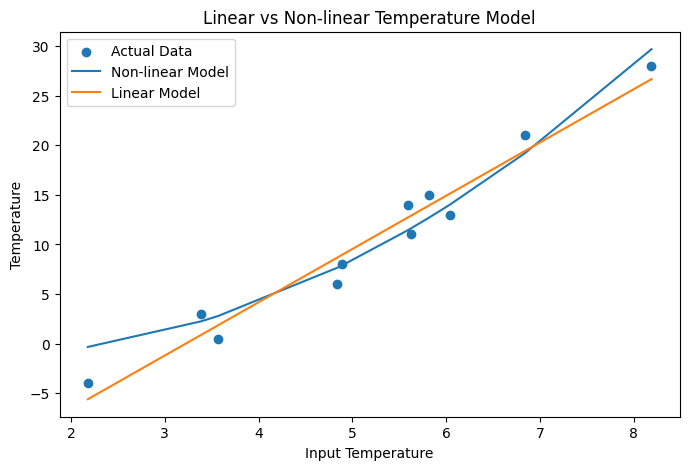

In [ ]:
t_u_sorted, indices = torch.sort(t_un)

with torch.no_grad():

    nonlinear_predictions = model(t_u_sorted, params)

    linear_predictions = linear_model(t_u_sorted, linear_params)


plt.figure(figsize=(8, 5))

plt.scatter(t_un.numpy(), t_c.numpy(), label='Actual Data')

plt.plot(t_u_sorted.numpy(), nonlinear_predictions.numpy(), label='Non-linear Model')

plt.plot(t_u_sorted.numpy(), linear_predictions.numpy(), label='Linear Model')

plt.xlabel('Input Temperature')
plt.ylabel('Temperature')
plt.title('Linear vs Non-linear Temperature Model')

plt.legend()
plt.show()